# Домашнее задание 1. PostgreSQL

## Этап 1. Подключение к БД, загрузка исходных CSV-файлов и первичная проверка
Сначала загружаем исходные данные из CSV в промежуточные (`raw_*`) таблицы как есть, чтобы проверить корректность типов данных.

In [6]:
%pip install psycopg2-binary ipython-sql sqlalchemy prettytable

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 3.8 MB 3.3 MB/s eta 0:00:01
     |████████████████████████████████| 2.2 MB 4.0 MB/s eta 0:00:01
     |████████████████████████████████| 46 kB 7.7 MB/s eta 0:00:011
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [23]:
import getpass
import psycopg2

# Имя текущего пользователя macOS (для подключения к локальному PostgreSQL через Homebrew)
db_user = getpass.getuser()
db_url = f"postgresql://{db_user}@localhost:5432/postgres"

# Расширение для выполнения SQL в ячейках через %%sql
%load_ext sql
%config SqlMagic.style = '_DEPRECATED_DEFAULT'
%sql $db_url

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


In [16]:
%%sql
--  Очистка таблиц в обратном порядке зависимостей (от дочерних к родительским)
DROP TABLE IF EXISTS raw_order_items;
DROP TABLE IF EXISTS raw_orders;
DROP TABLE IF EXISTS raw_products;
DROP TABLE IF EXISTS raw_customers;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
Done.
Done.
Done.
Done.


[]

### Создание и проверка таблицы из data/customers.csv

In [17]:
%%sql
-- Создаём таблицу raw_customers
CREATE TABLE raw_customers (
    customer_id INT PRIMARY KEY,
    first_name VARCHAR(100),
    last_name VARCHAR(100),
    gender VARCHAR(50),
    dob DATE,
    job_title VARCHAR(150),
    job_industry_category VARCHAR(100),
    wealth_segment VARCHAR(100),
    deceased_indicator BOOLEAN,
    owns_car BOOLEAN,
    address VARCHAR(255),
    postcode VARCHAR(10),
    state VARCHAR(50),
    country VARCHAR(100),
    property_valuation NUMERIC(10, 2)
);

 * postgresql://petrova.kseniya16@localhost:5432/postgres
Done.


[]

Загрузка данных из таблицы data/customers.csv

In [18]:
db_user = getpass.getuser()
conn = psycopg2.connect(dbname="postgres", user=db_user, host="localhost", port="5432")
cursor = conn.cursor()

with open("data/customers.csv", "r", encoding="utf-8") as f:
    cursor.copy_expert(
        "COPY raw_customers FROM STDIN WITH (FORMAT csv, HEADER true, DELIMITER ',')",
        f
    )

conn.commit()
cursor.close()
conn.close()
print("Файл customers.csv успешно загружен!")

Файл customers.csv успешно загружен!


Проверка данных 

In [24]:
%%sql
SELECT COUNT(*) FROM raw_customers;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
1 rows affected.


count
5000


In [26]:
%%sql
SELECT * FROM raw_customers LIMIT 5;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
5 rows affected.


customer_id,first_name,last_name,gender,dob,job_title,job_industry_category,wealth_segment,deceased_indicator,owns_car,address,postcode,state,country,property_valuation
1,Aria,Lee,Prefer not to say,1998-11-25,Software Engineer,Information Technology,Affluent Customer,False,False,394 Ocean Circuit,7234,TAS,Australia,12.06
2,Mei,Green,Prefer not to say,1985-04-17,Small Business Owner,Agriculture,Mass Customer,False,False,448 Garden Crescent,2522,NSW,Australia,7.98
3,Chloe,Patel,Male,1980-01-07,University Lecturer,Construction,Private Client,False,False,448 Flinders Drive,3475,VIC,Australia,5.83
4,Kai,Hall,Female,1990-08-09,Project Manager,Professional Services,Emerging Affluent,False,True,791 Park Street,3271,VIC,Australia,1.24
5,Aiden,Wilson,Non-binary,1949-12-04,Customer Success Manager,Education,High Net Worth,False,True,229 Queen Lane,7039,TAS,Australia,12.23


### Создание и проверка таблицы из data/products.csv

In [27]:
%%sql
CREATE TABLE raw_products (
    product_id INT PRIMARY KEY,
    brand VARCHAR(100),
    product_line VARCHAR(100),
    product_class VARCHAR(50),
    product_size VARCHAR(50),
    list_price NUMERIC(10, 2),
    standard_cost NUMERIC(10, 2)
);

 * postgresql://petrova.kseniya16@localhost:5432/postgres
Done.


[]

Загрузка данных из таблицы data/products.csv

In [28]:
db_user = getpass.getuser()
conn = psycopg2.connect(dbname="postgres", user=db_user, host="localhost", port="5432")
cursor = conn.cursor()

with open("data/products.csv", "r", encoding="utf-8") as f:
    cursor.copy_expert(
        "COPY raw_products FROM STDIN WITH (FORMAT csv, HEADER true, DELIMITER ',')",
        f
    )

conn.commit()
cursor.close()
conn.close()
print("Файл products.csv успешно загружен!")

Файл products.csv успешно загружен!


Проверка данных 

In [29]:
%%sql
SELECT COUNT(*) FROM raw_products;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
1 rows affected.


count
300


In [30]:
%%sql
SELECT * FROM raw_products LIMIT 10;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
10 rows affected.


product_id,brand,product_line,product_class,product_size,list_price,standard_cost
1,Solex,Touring,entry,large,1211.84,655.67
2,Giant Bicycles,Urban,professional,small,1836.39,1214.64
3,OHM Cycles,Cargo,professional,XXS,3645.34,1787.62
4,WeareA2B,Road,high,XL,868.00,507.60
5,Norco Bicycles,Gravel,value,medium,2046.44,887.75
6,Trek Bicycles,Electric,entry,XS,143.52,61.86
7,Avanti,Standard,high,XXL,1698.75,774.54
8,Merida,Mountain,entry,large,1197.53,734.11
9,Cannondale,BMX,professional,small,2014.40,1460.80
10,Specialized,Folding,entry,XXS,1598.50,1055.26


### Создание и проверка таблицы из data/orders.csv

In [31]:
%%sql
CREATE TABLE raw_orders (
    order_id INT PRIMARY KEY,
    customer_id INT REFERENCES raw_customers(customer_id),
    order_date TIMESTAMP,
    online_order BOOLEAN, 
    order_status VARCHAR(50)
);

 * postgresql://petrova.kseniya16@localhost:5432/postgres
Done.


[]

In [32]:
db_user = getpass.getuser()
conn = psycopg2.connect(dbname="postgres", user=db_user, host="localhost", port="5432")
cursor = conn.cursor()

with open("data/orders.csv", "r", encoding="utf-8") as f:
    cursor.copy_expert(
        "COPY raw_orders FROM STDIN WITH (FORMAT csv, HEADER true, DELIMITER ',')",
        f
    )

conn.commit()
cursor.close()
conn.close()
print("Файл orders.csv успешно загружен!")

Файл orders.csv успешно загружен!


In [33]:
%%sql
SELECT COUNT(*) FROM raw_orders;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
1 rows affected.


count
25000


In [40]:
%%sql
SELECT * FROM raw_orders LIMIT 10;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
10 rows affected.


order_id,customer_id,order_date,online_order,order_status
1,4129,2018-06-12 03:20:20,False,Processing
2,64,2018-02-19 01:53:24,False,Cancelled
3,879,2025-02-24 00:20:46,True,Processing
4,3313,2018-05-18 14:08:18,True,Cancelled
5,2859,2023-12-06 04:55:46,False,Refunded
6,1051,2023-09-02 01:45:19,True,Delivered
7,1013,2019-03-12 09:14:59,True,Cancelled
8,4481,2022-06-24 17:18:21,True,Approved
9,3555,2023-02-12 11:32:04,False,Delivered
10,3110,2019-10-18 21:02:01,False,Cancelled


### Создание и проверка таблицы из data/order_items.csv

In [35]:
%%sql
CREATE TABLE raw_order_items (
    order_item_id INT PRIMARY KEY, 
    order_id INT REFERENCES raw_orders(order_id),
    product_id INT REFERENCES raw_products(product_id),
    quantity INT,
    item_list_price_at_sale NUMERIC(10, 2),
    item_standard_cost_at_sale NUMERIC(10, 2)
);

 * postgresql://petrova.kseniya16@localhost:5432/postgres
Done.


[]

In [36]:
db_user = getpass.getuser()
conn = psycopg2.connect(dbname="postgres", user=db_user, host="localhost", port="5432")
cursor = conn.cursor()

with open("data/order_items.csv", "r", encoding="utf-8") as f:
    cursor.copy_expert(
        "COPY raw_order_items FROM STDIN WITH (FORMAT csv, HEADER true, DELIMITER ',')",
        f
    )

conn.commit()
cursor.close()
conn.close()
print("Файл order_items.csv успешно загружен!")

Файл order_items.csv успешно загружен!


In [38]:
%%sql
SELECT COUNT(*) FROM raw_order_items;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
1 rows affected.


count
50000


In [39]:
%%sql
SELECT * FROM raw_order_items LIMIT 10;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
10 rows affected.


order_item_id,order_id,product_id,quantity,item_list_price_at_sale,item_standard_cost_at_sale
1,1,137,2,2811.17,2170.50
2,1,158,2,575.58,310.93
3,2,288,4,2278.60,1489.90
4,2,18,1,1903.75,1154.75
5,3,26,4,3426.17,2452.86
6,3,151,1,1852.32,1078.74
7,4,232,4,1971.43,1323.07
8,4,105,1,3740.82,2426.08
9,5,96,4,4547.35,3189.43
10,5,22,3,2329.26,1551.51


## Этап 2: Визуализация бд как есть и нормализацию её до 3НФ

### Вид до нормализации

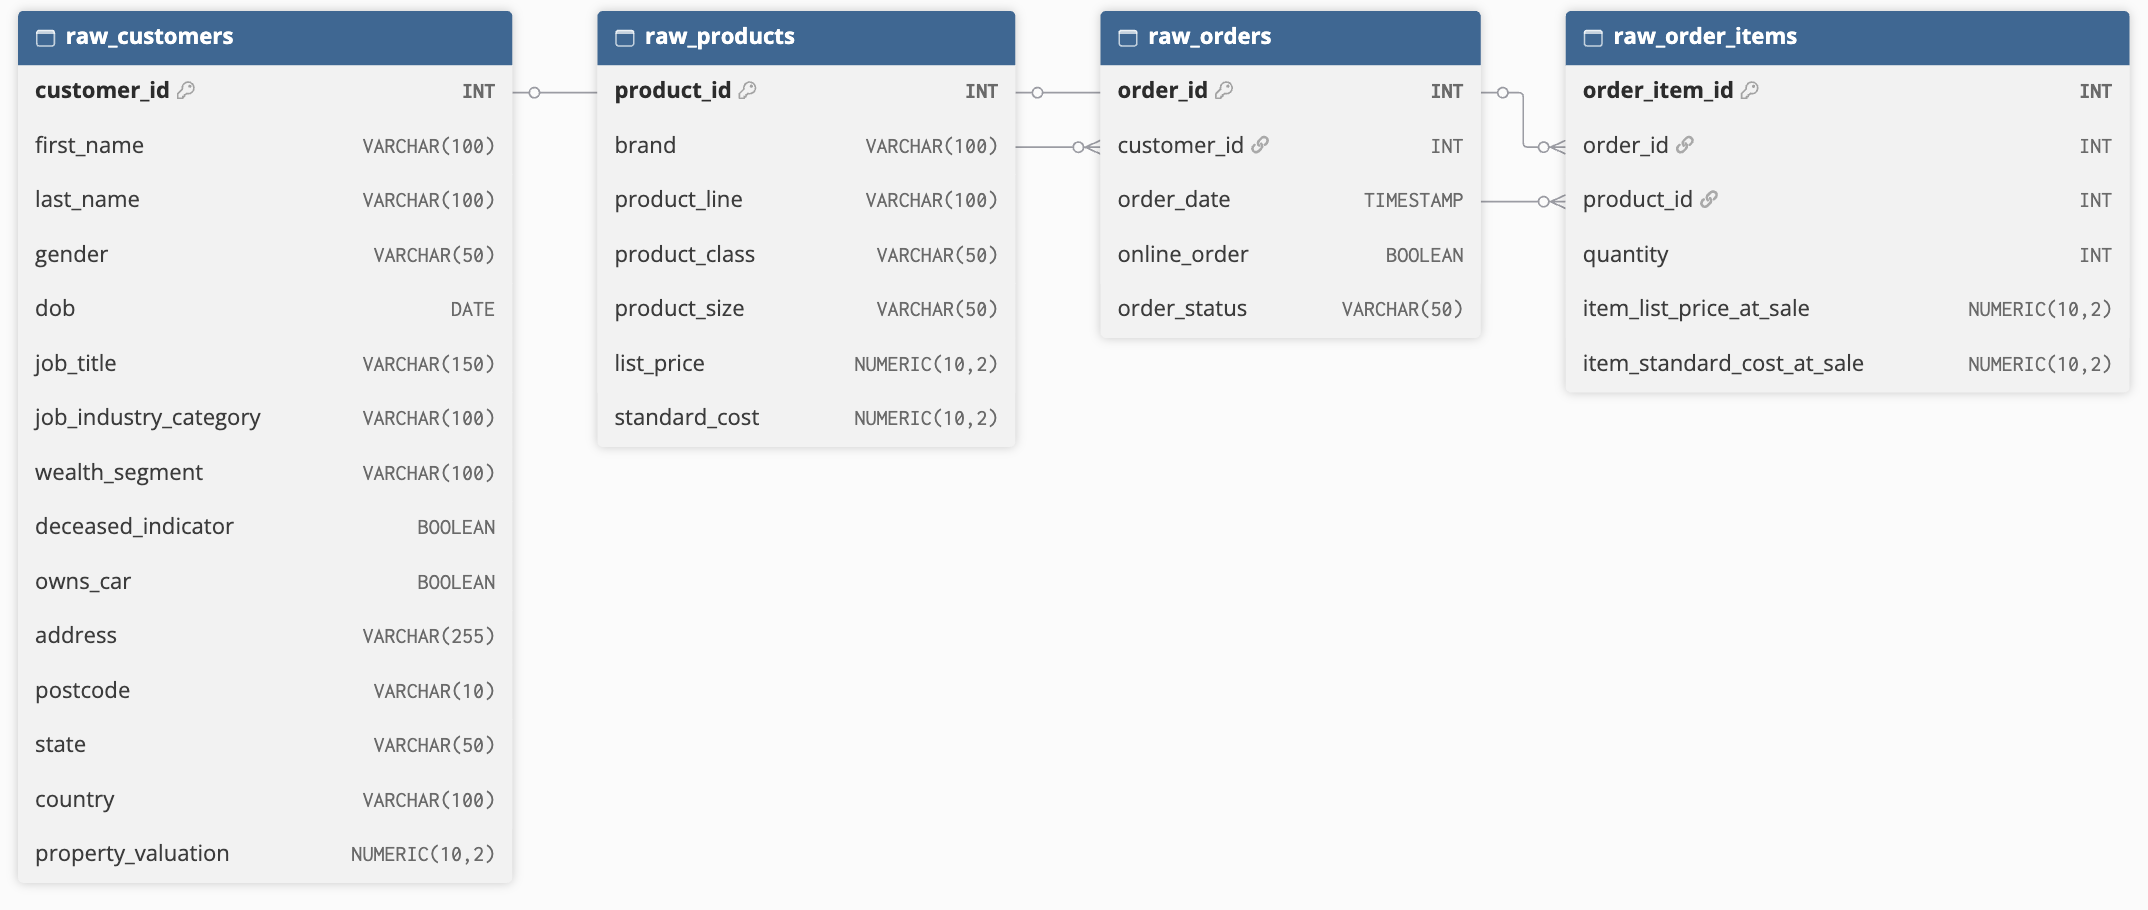

### Шаг 1. Приведение к первой нормальной форме (1НФ)

**Требования 1НФ (из конспекта):**
* Все атрибуты в таблице должны быть простыми.
* Все сохраняемые данные на пересечении столбцов и строк содержать лишь скалярные значения.
* В таблице не должно быть дублирующих строк, и у каждой записи должен быть уникальный первичный ключ (`PRIMARY KEY`).


1. Данные уже разделены на 4 отдельные таблицы. При загрузке CSV все поля успешно привелиcь к строгим типам данных. Визуально списков нет, но просмотреть всё главзами, конечно нереально. В текстовых полях могли остаться скрытые списки через `;`, `|` или в скобках `[]`.

In [ ]:
%%sql
SELECT 'raw_customers' AS table_name, COUNT(*) AS bad_rows
FROM raw_customers
WHERE CONCAT_WS('', first_name, last_name, gender, job_title, job_industry_category, wealth_segment, address, postcode, state, country) LIKE '%;%'
   OR CONCAT_WS('', first_name, last_name, gender, job_title, job_industry_category, wealth_segment, address, postcode, state, country) LIKE '%[%'
   OR CONCAT_WS('', first_name, last_name, gender, job_title, job_industry_category, wealth_segment, address, postcode, state, country) LIKE '%|%'

UNION ALL

SELECT 'raw_products', COUNT(*)
FROM raw_products
WHERE CONCAT_WS('', brand, product_line, product_class, product_size) LIKE '%;%'
   OR CONCAT_WS('', brand, product_line, product_class, product_size) LIKE '%[%'
   OR CONCAT_WS('', brand, product_line, product_class, product_size) LIKE '%|%'

UNION ALL

SELECT 'raw_orders', COUNT(*)
FROM raw_orders
WHERE order_status LIKE '%;%'
   OR order_status LIKE '%[%'
   OR order_status LIKE '%|%'


 * postgresql://petrova.kseniya16@localhost:5432/postgres
3 rows affected.


table_name,bad_rows
raw_customers,0
raw_products,0
raw_orders,0


2. Первичные ключи (PRIMARY KEY) были заданы сразу при создании таблиц. Загрузка всех 4 CSV-файлов прошла без ошибок нарушения уникальности значит в таблицах нет дублирующих ID и каждая строка уникальна.
3. Поле address (содержит номер дома и название улицы) формально можно было бы разделить на два отдельных атрибута, однако в аналитических запросах к базе используется только атрибут штата (state), поэтому в рамках этой задачи оставляем address единым неделимым строковым атрибутом.

### Шаг 2. Приведение ко второй нормальной форме (2НФ)

**Требования 2НФ:**
* Таблица уже находится в 1НФ.
* Каждый столбец, который не является ключом, зависит от первичного ключа.

**Анализ таблиц:**
1. Во всех четырёх исходных таблицах первичный ключ состоит из одного простого столбца.
2. Все неключевые поля логически относятся строго к своей сущности:
   * В `raw_customers` все поля относятся к клиенту и его месту жительства. Так как первичный ключ состоит всего из одного столбца (customer_id), ни один столбец не может зависеть от «части ключа», значит, 2НФ соблюдается.
   * В `raw_products` все характеристики (бренд, линейка, класс, размер, цены) описывают конкретный товар.
   * В `raw_orders` дата, статус и признак онлайн-заказа описывают конкретный заказ.
   * В `raw_order_items` количество, цена и себестоимость на момент продажи относятся только к конкретной позиции.
3. Ссылочная целостность уже была проверена. При создании таблиц я использовала ограничения внешнего ключа (`REFERENCES`), данные успешно загрузились.


Проверим что внешние ключи между таблицами работают корректно и в заказах нет ссылок на несуществующих клиентов или товары.


### Шаг 3. Приведение к третьей нормальной форме (3НФ)

**Требования 3НФ:**
* Таблица уже находится во 2НФ.
* Отсутствуют транзитивные зависимости.

**Анализ таблиц на транзитивные зависимости:**
1. В таблице `raw_customers` штат (`state`) и страна (`country`) зависят не от самого клиента (`customer_id`), а от его почтового индекса (`postcode`). Проверим в данных, действительно ли каждому индексу однозначно соответствует один штат и одна страна (нет ли индексов, привязанных сразу к двум разным штатам).
2. В таблице `raw_products` все характеристики относятся напрямую к конкретному товару и не определяют друг друга (у одного бренда могут быть разные линейки и размеры).
3. В `raw_orders` и `raw_order_items` все столбцы зависят только от своего ключа.


In [45]:
%%sql
SELECT postcode, COUNT(DISTINCT state) AS states_cnt, COUNT(DISTINCT country) AS countries_cnt
FROM raw_customers
WHERE postcode IS NOT NULL
GROUP BY postcode
HAVING COUNT(DISTINCT state) > 1 OR COUNT(DISTINCT country) > 1;


 * postgresql://petrova.kseniya16@localhost:5432/postgres
12 rows affected.


postcode,states_cnt,countries_cnt
2601,2,1
2602,2,1
2603,2,1
2606,2,1
2607,2,1
2608,2,1
2609,2,1
2610,2,1
2613,2,1
2616,2,1


Предыдущий запрос показал, что для некоторых почтовых индексов (например, `2601`, `2602`, `2603`) в таблице указано сразу два разных штата (`states_cnt = 2`). Выведем уникальные комбинации индекса, штата и страны для первых трёх таких индексов, чтобы понять причину: это разное написание одного и того же штата или один индекс действительно относится к двум разным регионам.


In [46]:
%%sql
SELECT DISTINCT postcode, state, country
FROM raw_customers
WHERE postcode IN ('2601', '2602', '2603')
ORDER BY postcode, state;


 * postgresql://petrova.kseniya16@localhost:5432/postgres
6 rows affected.


postcode,state,country
2601,ACT,Australia
2601,NSW,Australia
2602,ACT,Australia
2602,NSW,Australia
2603,ACT,Australia
2603,NSW,Australia


**Вывод:**
1. Проверка показала, что один и тот же почтовый индекс может относиться к двум разным регионам (`ACT` и `NSW`). Поэтому считать, что `postcode` однозначно определяет `state` нельзя.
2. При этом каждый штат (`state`) однозначно определяет страну (`country` — `Australia`), что создаёт транзитивную зависимость `customer_id → state → country`.
3. Чтобы привести схему к 3НФ без потери данных, выносим географию в справочник `states` (`state PK, country`), а в финальной таблице **`customers`** оставляем `postcode` и внешний ключ `state`.


Создаём финальные таблицы

In [47]:
%%sql
DROP TABLE IF EXISTS order_items CASCADE;
DROP TABLE IF EXISTS orders CASCADE;
DROP TABLE IF EXISTS products CASCADE;
DROP TABLE IF EXISTS customers CASCADE;
DROP TABLE IF EXISTS states CASCADE;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
Done.
Done.
Done.
Done.
Done.


[]

In [48]:
%%sql
-- Справочник штатов и стран

CREATE TABLE states (
    state VARCHAR(50) PRIMARY KEY,
    country VARCHAR(100) NOT NULL
);

-- Финальная таблица клиентов
CREATE TABLE customers (
    customer_id INT PRIMARY KEY,
    first_name VARCHAR(100) NOT NULL,
    last_name VARCHAR(100) NOT NULL,
    gender VARCHAR(50),
    dob DATE,
    job_title VARCHAR(150),
    job_industry_category VARCHAR(100),
    wealth_segment VARCHAR(100),
    deceased_indicator BOOLEAN NOT NULL,
    owns_car BOOLEAN NOT NULL,
    address VARCHAR(255),
    postcode VARCHAR(10),
    state VARCHAR(50) REFERENCES states(state),
    property_valuation NUMERIC(10, 2)
);

 * postgresql://petrova.kseniya16@localhost:5432/postgres
Done.
Done.


[]

In [50]:
%%sql
-- Наполняем справочник штатов
INSERT INTO states (state, country)
SELECT DISTINCT state, country
FROM raw_customers
WHERE state IS NOT NULL;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
8 rows affected.


[]

In [51]:
%%sql
-- Наполняем таблицу клиентов (без дублирующегося столбца country)
INSERT INTO customers (
    customer_id, first_name, last_name, gender, dob,
    job_title, job_industry_category, wealth_segment,
    deceased_indicator, owns_car, address, postcode, state, property_valuation
)
SELECT
    customer_id, first_name, last_name, gender, dob,
    job_title, job_industry_category, wealth_segment,
    deceased_indicator, owns_car, address, postcode, state, property_valuation
FROM raw_customers;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
5000 rows affected.


[]

In [52]:
%%sql
-- Финальная таблица продуктов
CREATE TABLE products (
    product_id INT PRIMARY KEY,
    brand VARCHAR(100),
    product_line VARCHAR(100),
    product_class VARCHAR(50),
    product_size VARCHAR(50),
    list_price NUMERIC(10, 2) NOT NULL CHECK (list_price >= 0),
    standard_cost NUMERIC(10, 2) CHECK (standard_cost >= 0)
);

-- Финальная таблица заказов
CREATE TABLE orders (
    order_id INT PRIMARY KEY,
    customer_id INT NOT NULL REFERENCES customers(customer_id),
    order_date TIMESTAMP NOT NULL,
    online_order BOOLEAN,
    order_status VARCHAR(50) NOT NULL
);

-- Финальная таблица позиций заказов
CREATE TABLE order_items (
    order_item_id INT PRIMARY KEY,
    order_id INT NOT NULL REFERENCES orders(order_id),
    product_id INT NOT NULL REFERENCES products(product_id),
    quantity INT NOT NULL CHECK (quantity > 0),
    item_list_price_at_sale NUMERIC(10, 2) NOT NULL CHECK (item_list_price_at_sale >= 0),
    item_standard_cost_at_sale NUMERIC(10, 2) CHECK (item_standard_cost_at_sale >= 0)
);

 * postgresql://petrova.kseniya16@localhost:5432/postgres
Done.
Done.
Done.


[]

In [ ]:
%%sql
-- Переносим данные
INSERT INTO products SELECT * FROM raw_products;
INSERT INTO orders SELECT * FROM raw_orders;
INSERT INTO order_items SELECT * FROM raw_order_items;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
300 rows affected.
25000 rows affected.
50000 rows affected.


[]

### Схема после нормализации
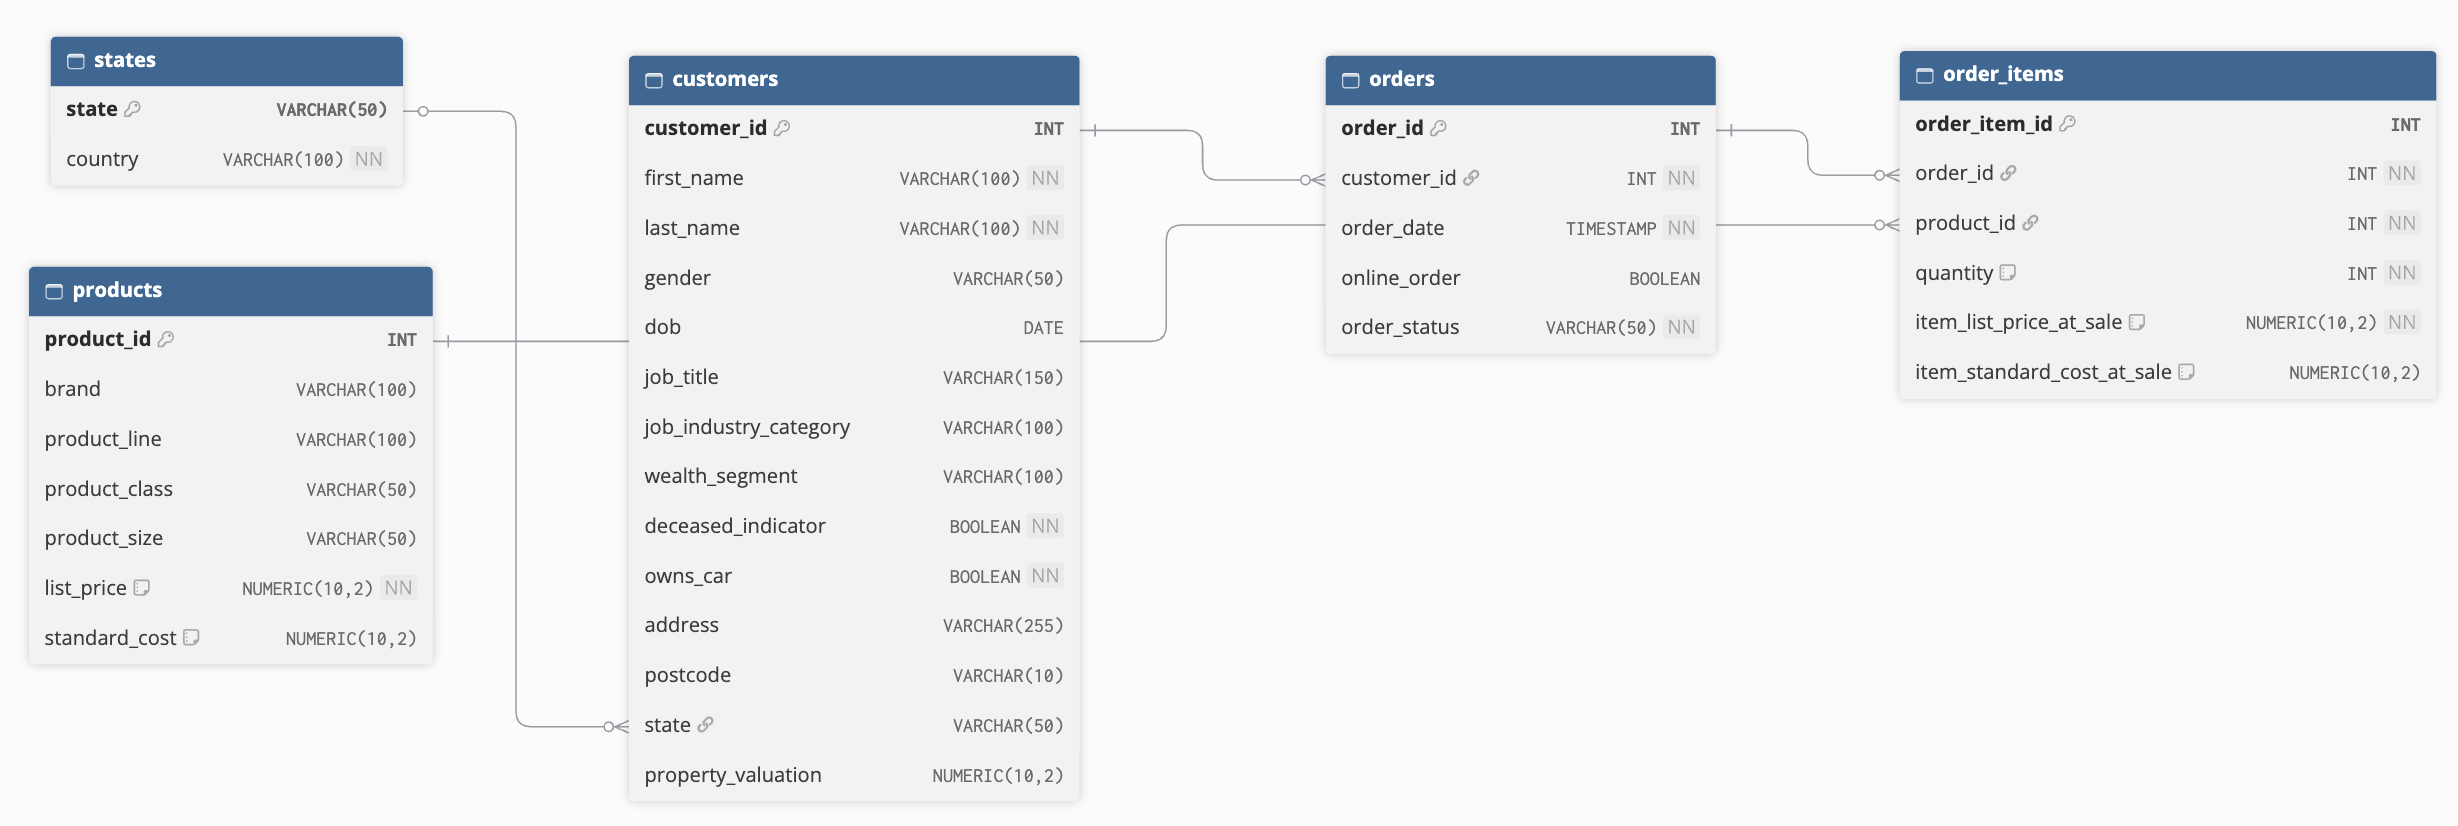

## Этап 3: Выполнить запросы

1. Выведите id продукта и среднюю цену продажи (item_list_price_at_sale) для 5 продуктов с самой высокой средней ценой продажи.

In [54]:
%%sql
SELECT product_id, AVG(item_list_price_at_sale) as avg_price
FROM order_items 
GROUP BY product_id
ORDER BY avg_price DESC
LIMIT 5;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
5 rows affected.


product_id,avg_price
102,4785.2817218543046358
208,4705.4832142857142857
270,4641.4406626506024096
163,4456.2792613636363636
76,4444.5248924731182796


2. Рассчитайте общую стоимость заказа (item_list_price_at_sale * quantity) для каждого бренда продукта.

In [ ]:
%%sql
SELECT products.brand, SUM(order_items.item_list_price_at_sale * order_items.quantity) as full_sum
FROM order_items 
JOIN products on order_items.product_id = products.product_id
GROUP BY products.brand;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
18 rows affected.


brand,full_sum
Trek Bicycles,14778340.33
Orbea,13263805.74
Giant Bicycles,10654989.26
Merida,15415175.91
Focus,9952752.69
OHM Cycles,14602909.95
Bianchi,14187712.33
Avanti,11079424.78
Scott,14693791.88
WeareA2B,19115387.51


3.Подсчитайте количество заказов за каждый месяц для каждого года. То есть необходимо вывести год, месяц и количество заказов.

In [60]:
%%sql
SELECT EXTRACT(YEAR FROM order_date) as year, EXTRACT(MONTH FROM order_date) as month, COUNT(*) 
FROM orders
GROUP BY year, month
ORDER BY year;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
116 rows affected.


year,month,count
2017,1,218
2017,2,187
2017,3,232
2017,4,221
2017,5,215
2017,6,225
2017,7,220
2017,8,207
2017,9,200
2017,10,217


4. Для каждой продуктовой линейки (product_line) найдите продукт с самой высокой стандартной стоимостью (standard_cost). Выведите id продукта, линейку продукта и стандартную стоимость.

In [61]:
%%sql
SELECT product_id, product_line, standard_cost
FROM products
WHERE (product_line, standard_cost) IN (
    SELECT product_line, MAX(standard_cost)
    FROM products
    GROUP BY product_line
);

 * postgresql://petrova.kseniya16@localhost:5432/postgres
10 rows affected.


product_id,product_line,standard_cost
96,Electric,3189.43
101,Touring,2049.62
102,Urban,3169.71
134,Road,3362.69
177,Standard,2646.57
185,Gravel,2784.97
193,Cargo,3394.73
209,BMX,2339.31
250,Folding,3682.24
298,Mountain,2812.02


5. Подсчитайте количество заказов и общую стоимость заказов для каждого статуса заказа (order_status). Общую стоимость заказа необходимо рассчитать как цену продукта на момент продажи, умноженную на количество единиц продукта в заказе.

In [62]:
%%sql
SELECT order_status, COUNT(DISTINCT orders.order_id), SUM(order_items.item_list_price_at_sale * order_items.quantity) as full_sum
FROM orders
LEFT JOIN order_items ON orders.order_id = order_items.order_id
GROUP BY orders.order_status;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
6 rows affected.


order_status,count,full_sum
Approved,4114,40840554.03
Cancelled,4162,41886902.51
Delivered,4113,40254796.60
Processing,4283,42612082.52
Refunded,4181,42749707.85
Shipped,4147,41628232.95


6. Найдите клиентов, у которых нет ни одного заказа. Выведите id клиента, фамилию и имя.

In [63]:
%%sql
SELECT customers.customer_id, last_name, first_name
FROM customers
LEFT JOIN orders ON customers.customer_id = orders.customer_id
WHERE orders.order_id IS NULL;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
38 rows affected.


customer_id,last_name,first_name
1582,Khan,Leila
252,Campbell,Max
4475,Ryan,Henry
2414,Khan,Ethan
841,Carter,Priya
2967,Allen,James
3992,Khan,Sophie
178,Campbell,Mei
2372,Green,Leila
4959,Young,Chloe


7. Для каждого штата найдите клиента с самой высокой и самой низкой оценкой стоимости имущества (property_valuation). Выведите штат, оценку стоимости имущества, фамилию и имя клиента.

In [65]:
%%sql
SELECT 
    customers.state, 
    customers.property_valuation, 
    customers.last_name, 
    customers.first_name
FROM customers 
JOIN (
    SELECT 
        state, 
        MIN(property_valuation) AS min_valuation, 
        MAX(property_valuation) AS max_valuation
    FROM customers
    WHERE state IS NOT NULL
    GROUP BY state
) min_max_table
    ON customers.state = min_max_table.state 
    AND (customers.property_valuation = min_max_table.min_valuation
    OR customers.property_valuation = min_max_table.max_valuation)
ORDER BY customers.state;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
21 rows affected.


state,property_valuation,last_name,first_name
ACT,1.04,White,Ethan
ACT,14.99,Martin,William
NSW,1.03,Smith,Sophie
NSW,14.96,Kim,Aiden
NT,1.03,Taylor,Mia
NT,1.03,Smith,Mateo
NT,14.98,Kim,Aria
QLD,14.96,Smith,William
QLD,1.02,Walker,Ethan
SA,15.00,Carter,Henry


8. Найдите клиентов, которые покупали продукты только из одной продуктовой линейки (product_line). Выведите id клиента, линейку продукта и количество заказов.

In [67]:
%%sql
SELECT 
    orders.customer_id, 
    MIN(products.product_line) AS product_line, 
    COUNT(DISTINCT orders.order_id) AS order_count
FROM orders
JOIN order_items ON orders.order_id = order_items.order_id
JOIN products ON order_items.product_id = products.product_id
WHERE products.product_line IS NOT NULL
GROUP BY orders.customer_id
HAVING COUNT(DISTINCT products.product_line) = 1
ORDER BY orders.customer_id;


 * postgresql://petrova.kseniya16@localhost:5432/postgres
16 rows affected.


customer_id,product_line,order_count
8,Urban,1
213,Urban,1
431,Road,1
692,Electric,2
773,Mountain,1
890,Mountain,1
911,Touring,1
2432,Standard,1
2644,Gravel,1
3175,Gravel,1


9. Для каждой категории продуктов рассчитайте процент отмененных заказов (order_status = 'Cancelled').

In [68]:
%%sql
SELECT 
    products.product_line,
    ROUND(
        100.0 * COUNT(DISTINCT orders.order_id) FILTER (WHERE orders.order_status = 'Cancelled')
        / COUNT(DISTINCT orders.order_id),
        2
    ) AS cancelled_percent
FROM products
JOIN order_items ON products.product_id = order_items.product_id
JOIN orders ON order_items.order_id = orders.order_id
WHERE products.product_line IS NOT NULL
GROUP BY products.product_line;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
10 rows affected.


product_line,cancelled_percent
BMX,17.24
Cargo,16.98
Electric,16.37
Folding,16.83
Gravel,16.74
Mountain,16.65
Road,16.23
Standard,16.78
Touring,15.22
Urban,17.12


10. Разделите клиентов на сегменты на основе количества заказов и подсчитайте количество клиентов в каждом сегменте:
сегмент High, если количество заказов больше 10;
сегмент Medium, если количество заказов от 5 до 10;
иначе сегмент Low

In [69]:
%%sql
WITH customer_orders AS (
    SELECT 
        customers.customer_id,
        COUNT(orders.order_id) AS orders_count
    FROM customers
    LEFT JOIN orders ON customers.customer_id = orders.customer_id
    GROUP BY customers.customer_id
)
SELECT 
    CASE 
        WHEN orders_count > 10 THEN 'High'
        WHEN orders_count BETWEEN 5 AND 10 THEN 'Medium'
        ELSE 'Low'
    END AS segment,
    COUNT(*)
FROM customer_orders
GROUP BY segment;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
3 rows affected.


segment,count
Medium,2692
High,75
Low,2233


11. Для всех клиентов выведите имена, фамилии, профессии, а также длительность максимального интервала (в днях) между двумя последовательными заказами. Необходимо исключить клиентов, у которых только один заказ или меньше.

In [70]:
%%sql
SELECT 
    customers.first_name,
    customers.last_name,
    customers.job_title,
    MAX(next_order_day - order_day) AS max_interval_days
FROM (
    SELECT 
        o1.customer_id,
        o1.order_date::DATE AS order_day,
        MIN(o2.order_date::DATE) AS next_order_day
    FROM orders o1
    JOIN orders o2 
        ON o1.customer_id = o2.customer_id 
        AND (o2.order_date, o2.order_id) > (o1.order_date, o1.order_id)
    GROUP BY o1.customer_id, o1.order_id, o1.order_date
) intervals
JOIN customers ON intervals.customer_id = customers.customer_id
GROUP BY customers.customer_id, customers.first_name, customers.last_name, customers.job_title;

 * postgresql://petrova.kseniya16@localhost:5432/postgres
4784 rows affected.


first_name,last_name,job_title,max_interval_days
Lucas,Young,Marketing Specialist,2106
Noah,Jones,Teacher,494
Fatima,Chen,Data Analyst,1401
Chloe,Martin,Product Manager,1519
Harper,Baker,Chef,952
Lucas,Nguyen,Small Business Owner,967
Oliver,Smith,Mechanic,1601
Aiden,Johnson,Pharmacist,998
Priya,Green,Data Analyst,1527
Mateo,Nguyen,Financial Adviser,1347


## Выводы, рефлексия и сдача

### Рефлексия после выполнения (заполните здесь)

**1. Что было задано и что получилось**:

`Ответ: Надо было проанализировать данные и привести их к 3НФ. После этого выполнить запросы. В принципе все получилось.`

**2. Как выполняли**: что сработало сразу, где застряли и как выбрались:

`Ответ: Как ни странно застряла при оформлении, хотелось в ноутбуке, но он не посазывает - это раздражает. Но просто в .sql неудобно, поэтому полчилось два файла. И потребовалось время чтобы настроить ноутбук. В 1НФ не уверена что делать с полем адреса, оно содержит номер дома и название улицы, так как эти данные не нужны были при запросах, я решила оставить как есть. При нормализации 3НФ были небольшие трудности, так как оказалось что к некоторым индексам привязано сразу два штата. Если бы вынесла postcode первичным ключом справочника, потерялись бы штаты части клиентов. Некоторые запросы были сложноваты, при работе делала итерационо, сначала запускала одни запросы смотрела на вывод, потом добавляла условия, чтобы контролировать процесс.  `

**3. Использование ИИ**: цель, использованные промпты, где помощник ошибся и как вы это поняли. Если не использовали, так и напишите:

`Ответ: В основном использовала ИИ для настройки окружения, что скачать для подсказок, что скачать для визуализац и тд. И про ошибку 
KeyError: 'DEFAULT' предложил дописать %config SqlMagic.style = '_DEPRECATED_DEFAULT' "`

**4. Что осталось непонятным** (честный список, он поможет на консультации):

`Ответ: Вроде понятно, больше практики для уверенности`

**5. Самооценка по критериям задания**:

`Ответ: Оцениваю на 10 балов, все запросы выполнены. Представлены схемы до и посел нормализации`

**6. Дополнительный вопрос: обратная связь по заданию.** Что было ценно, что сложно, а что, на ваш взгляд, требует доработки?

`Ответ: Опыт написания запросов. Полезно что вроде такие простые задачи, но решаются достаточно массивным запросом.`

> Напоминание: рефлексия пишется своими словами, без помощи ИИ.

